# Every sequential ramp on the same curves

**Shows:** one panel per ramp. Each panel draws the same six decaying curves in six shades of that ramp,
darkest for the slowest decay.

**Graph type:** ordered line series coloured from a ramp (`lf.ramp`).

**Writes:** `palettes.svg` next to this notebook.

**To tweak:** change the capitalised settings at the top of the **Figure** cell and re-run that cell.

**Runs on:** the default `python3` kernel: Python 3.10 or newer with labfigs installed.

**To run it all:** `jupyter nbconvert --to notebook --execute --inplace palettes.ipynb`, which also saves the figures in this notebook.

In [1]:
import numpy as np

import labfigs as lf

lf.use()

## Data

- `x`: positions along the x axis, length 200

The curves are `exp(-rate * x)` for `rate` 1, 2, 3, ... and are computed where they are drawn.

In [2]:
x = np.linspace(0, 1, 200)

## Figure

Settings at the top of the cell:

- `NAME`: file name of the figure, without `.svg`
- `WIDTH`, `PANEL_ASPECT`: figure width in inches, and the height of one panel divided by its width
- `ROWS`, `COLUMNS`: shape of the grid; it needs one panel per entry of `RAMPS`
- `RAMPS`: ramp of each panel, in order; any ramp or scheme name
- `SHADES`: number of curves, and so of shades taken from each ramp
- `LINE_WIDTH`: width of the curves in points
- `X_LABEL`, `Y_LABEL`, `TICKS`: the shared axes

PosixPath('palettes.svg')

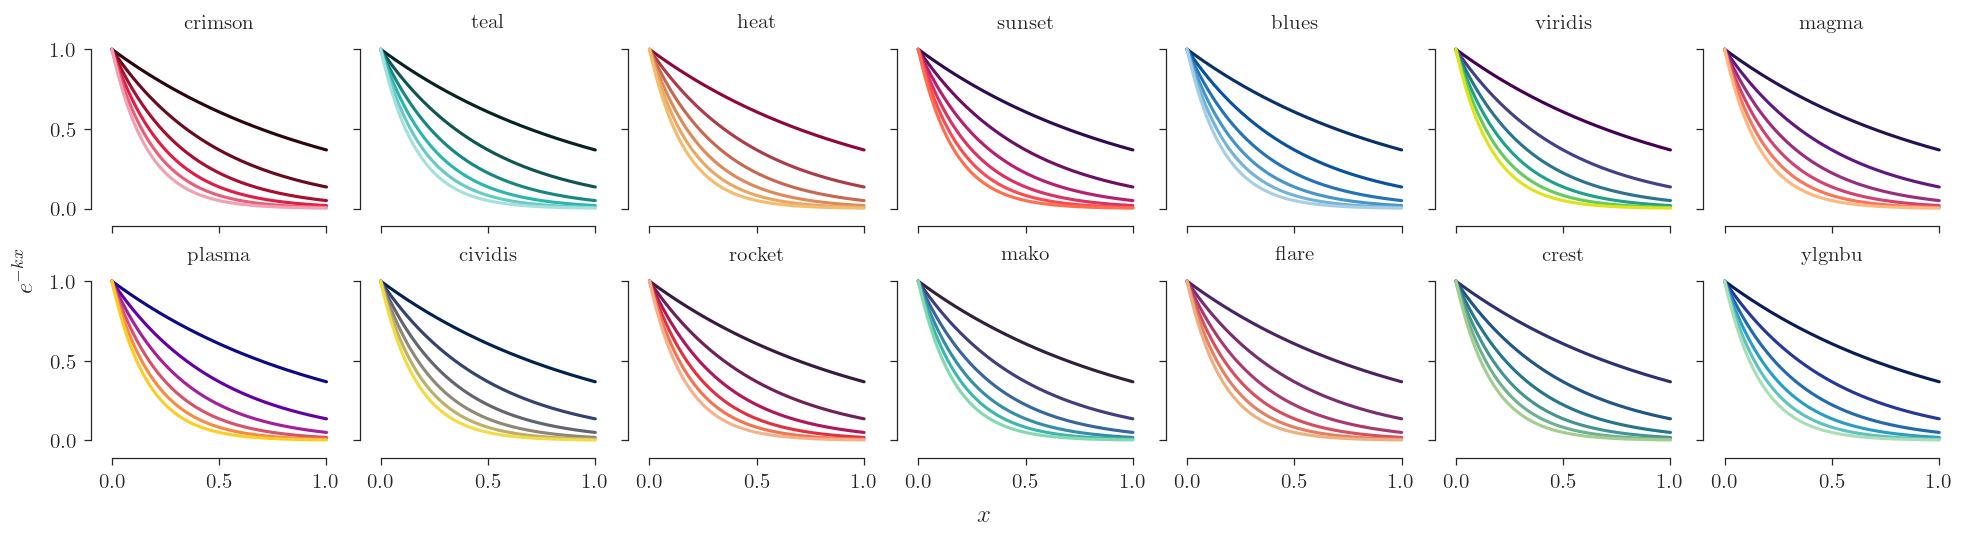

In [3]:
NAME = "palettes"
WIDTH, PANEL_ASPECT = 13, 0.75
ROWS, COLUMNS = 2, 7
RAMPS = tuple(lf.RAMPS)
SHADES = 6
LINE_WIDTH = 1.5
X_LABEL, Y_LABEL, TICKS = "$x$", r"$e^{-kx}$", [0, 0.5, 1]

palettes = {name: lf.ramp(SHADES, name) for name in RAMPS}
fig, axes = lf.subplots(ROWS, COLUMNS, width=WIDTH, aspect=PANEL_ASPECT, sharex=True, sharey=True)
for ax, (name, colors) in zip(axes.flat, palettes.items()):
    for rate, color in enumerate(colors, start=1):
        ax.plot(x, np.exp(-rate * x), color=color, lw=LINE_WIDTH)
    ax.set(title=name, xticks=TICKS, yticks=TICKS)
fig.supxlabel(X_LABEL)
fig.supylabel(Y_LABEL)
lf.save(fig, NAME)

## Checks

Fails if a panel has no ramp or a ramp gives fewer than three shades. Nothing to tweak.

In [4]:
assert len(palettes) == axes.size and all(len(c) >= 3 for c in palettes.values())